# T20 · Phân cụm đối tác thương mại

Phân cụm 39 đối tác từ T18 bằng 22 đặc trưng đã chuẩn hóa: 21 tỷ trọng phần HS và CAGR 2015–2024. Notebook so sánh K-Means (k = 2–8), kiểm tra độ ổn định giữa hai seed và đối chiếu với phân cụm phân cấp Ward.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

input_names = (
    'partner_features.csv',
    'partner_features_standardized.csv',
    'partner_feature_columns.csv',
)
root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if all((p / 'data' / 'clean' / name).is_file() for name in input_names)),
    None,
)
if root is None:
    raise FileNotFoundError('Không tìm thấy các đầu ra T18 trong data/clean/.')

clean = root / 'data' / 'clean'
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from notebooks.house_style.house_style import (
    ACCENT_COLOR, SOURCE, apply_style, declutter, format_number,
)
identity = ['partner_code', 'partner_iso3', 'partner_name']
df_raw = pd.read_csv(
    clean / input_names[0],
    dtype={'partner_code': 'string', 'partner_iso3': 'string'},
)
df_std = pd.read_csv(
    clean / input_names[1],
    dtype={'partner_code': 'string', 'partner_iso3': 'string'},
)
manifest = pd.read_csv(clean / input_names[2]).sort_values('feature_order')
features = manifest['feature'].tolist()

if (
    manifest['feature_order'].tolist() != list(range(1, len(features) + 1))
    or manifest['feature'].isna().any()
    or len(features) != len(set(features))
    or df_raw[identity].isna().any().any()
    or df_std[identity].isna().any().any()
    or df_raw['partner_code'].duplicated().any()
    or df_std['partner_code'].duplicated().any()
    or df_std.columns.tolist() != identity + features
):
    raise ValueError('Kiểm tra định danh và danh sách đặc trưng đầu ra T18.')

df_std = df_raw[identity].merge(
    df_std, on=identity, how='left', validate='one_to_one', indicator=True
)
if df_std['_merge'].ne('both').any():
    raise ValueError('Bảng chuẩn hóa T18 không khớp định danh với bảng gốc.')
df_std = df_std.drop(columns='_merge')
X = df_std[features].to_numpy(dtype=float)
if len(X) < 9 or not np.isfinite(X).all():
    raise ValueError('Cần ít nhất 9 đối tác và ma trận đặc trưng hữu hạn.')

print(f'Đầu vào: {len(X)} đối tác × {len(features)} đặc trưng z-score.')

Đầu vào: 39 đối tác × 22 đặc trưng z-score.


## 1. Elbow và Silhouette

## Lựa chọn k = 4

Silhouette đạt cao nhất tại k = 2 (0.1763), nhưng hai nhóm quá gộp so với mục tiêu phân khúc đối tác theo hồ sơ thương mại. Không chọn k = 3 vì độ ổn định giữa hai lần khởi tạo thấp (ARI = 0.1516; seed 42 và 2026). Chọn k = 4 làm phương án phân khúc vận hành: ARI giữa hai seed tăng lên 0.5775 và mức đồng thuận với Ward đạt 0.9063. Đây là sự đánh đổi giữa độ chi tiết và độ ổn định, không phải bằng chứng rằng k = 4 tối ưu tuyệt đối; Silhouette toàn dải còn thấp và k = 4 tạo cụm đơn lẻ cần được nêu rõ khi diễn giải.

Bảng đánh giá số cụm k (random_state=42):
 k    inertia  silhouette
 2 758.188899    0.176325
 3 681.710624    0.084055
 4 620.218597    0.100068
 5 576.443863    0.097928
 6 524.349483    0.105843
 7 477.994807    0.080267
 8 435.953514    0.093600


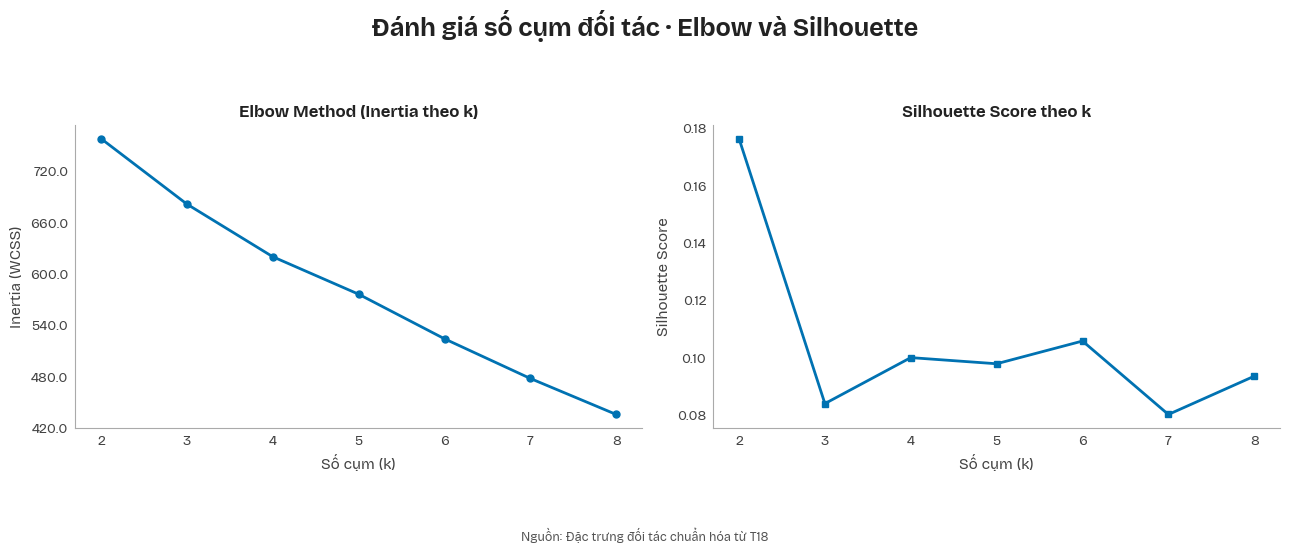

In [2]:
k_values = list(range(2, min(9, len(X))))
inertias = []
silhouettes = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X)
    if len(np.unique(labels)) != k:
        raise ValueError(f'K-Means chỉ tạo được {len(np.unique(labels))} cụm khi k={k}.')
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X, labels))

metrics_df = pd.DataFrame(
    {'k': k_values, 'inertia': inertias, 'silhouette': silhouettes}
)
print('Bảng đánh giá số cụm k (random_state=42):')
print(metrics_df.to_string(index=False))

with apply_style():
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    axes[0].plot(k_values, inertias, marker='o', color=ACCENT_COLOR)
    axes[0].set_title('Elbow Method (Inertia theo k)', fontsize=12)
    axes[0].set_xlabel('Số cụm (k)')
    axes[0].set_ylabel('Inertia (WCSS)')
    axes[0].yaxis.set_major_formatter(
        FuncFormatter(lambda value, _: format_number(value, 1))
    )
    axes[1].plot(k_values, silhouettes, marker='s', color=ACCENT_COLOR)
    axes[1].set_title('Silhouette Score theo k', fontsize=12)
    axes[1].set_xlabel('Số cụm (k)')
    axes[1].set_ylabel('Silhouette Score')
    axes[1].yaxis.set_major_formatter(
        FuncFormatter(lambda value, _: format_number(value, 2))
    )
    declutter(axes[0])
    declutter(axes[1])
    fig.suptitle('Đánh giá số cụm đối tác · Elbow và Silhouette')
    fig.supxlabel('Nguồn: Đặc trưng đối tác chuẩn hóa từ T18', **SOURCE)
    fig.tight_layout(rect=(0, 0.06, 1, 0.92))
    plt.show()

## 2. Độ ổn định và phân cụm phân cấp

ARI được tính giữa cùng số cụm, với seed 42 và 2026. Chọn k = 4 cho nhãn phân cụm bàn giao; Ward là đối chiếu độc lập. Nhãn `cluster` trong CSV là K-Means (k = 4, seed = 42); `hc_cluster` giữ nhãn Ward. Mã cụm không biểu thị thứ hạng.

Độ ổn định K-Means (k=3) giữa seed 42 và 2026: ARI = 0.1516
Độ ổn định K-Means (k=4) giữa seed 42 và 2026: ARI = 0.5775
Bảng đối chiếu nhãn giữa hai seed:
seed_2026   0   1  2  3
seed_42                
0           2  18  0  0
1           1   2  3  0
2          11   1  0  0
3           0   0  0  1
K-Means vs Hierarchical (ward): ARI = 0.9063
Bảng đối chiếu K-Means và Hierarchical:
hc_ward_cluster  0  1   2   3
kmeans_cluster               
0                0  0  20   0
1                6  0   0   0
2                2  0   0  10
3                0  1   0   0


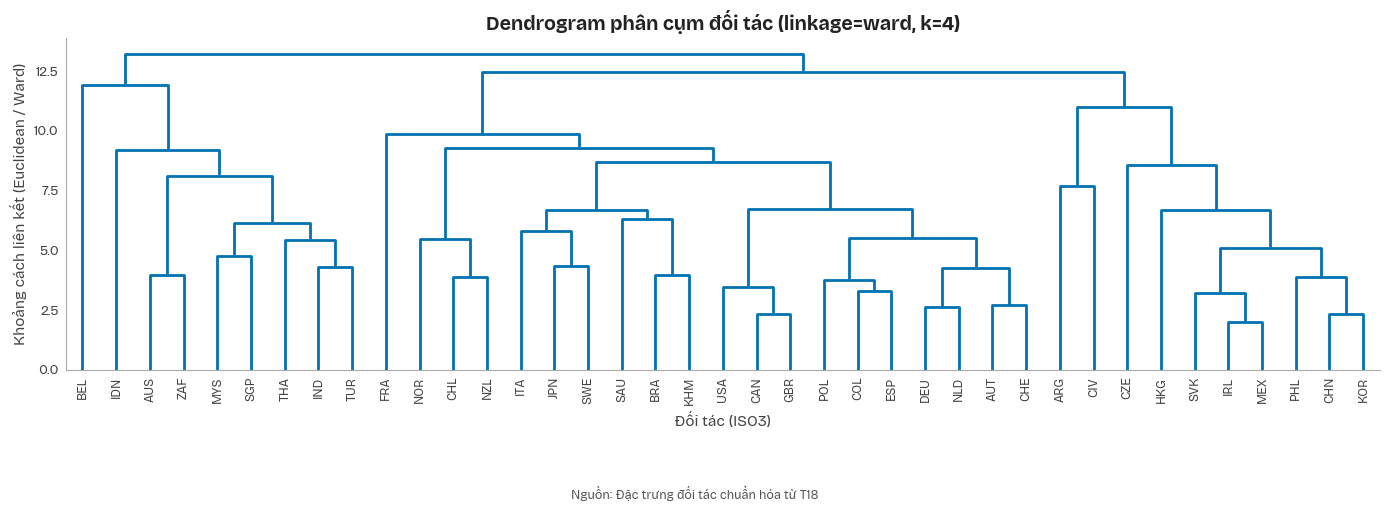

In [3]:
SEED_1 = 42
SEED_2 = 2026
K3_SEED_1 = KMeans(n_clusters=3, random_state=SEED_1, n_init=20).fit_predict(X)
K3_SEED_2 = KMeans(n_clusters=3, random_state=SEED_2, n_init=20).fit_predict(X)
ari_k3_seeds = adjusted_rand_score(K3_SEED_1, K3_SEED_2)
print(f'Độ ổn định K-Means (k=3) giữa seed {SEED_1} và {SEED_2}: ARI = {ari_k3_seeds:.4f}')

CHOSEN_K = 4

km_1 = KMeans(n_clusters=CHOSEN_K, random_state=SEED_1, n_init=20)
km_2 = KMeans(n_clusters=CHOSEN_K, random_state=SEED_2, n_init=20)
labels_seed1 = km_1.fit_predict(X)
labels_seed2 = km_2.fit_predict(X)
if len(np.unique(labels_seed1)) != CHOSEN_K or len(np.unique(labels_seed2)) != CHOSEN_K:
    raise ValueError('K-Means không tạo đủ số cụm đã chọn.')

ari_seeds = adjusted_rand_score(labels_seed1, labels_seed2)
print(f'Độ ổn định K-Means (k={CHOSEN_K}) giữa seed {SEED_1} và {SEED_2}: ARI = {ari_seeds:.4f}')
print('Bảng đối chiếu nhãn giữa hai seed:')
print(pd.crosstab(
    pd.Series(labels_seed1, name=f'seed_{SEED_1}'),
    pd.Series(labels_seed2, name=f'seed_{SEED_2}'),
))

LINKAGE_METHOD = 'ward'
Z = linkage(X, method=LINKAGE_METHOD)
labels_hc = fcluster(Z, t=CHOSEN_K, criterion='maxclust') - 1
if len(np.unique(labels_hc)) != CHOSEN_K:
    raise ValueError('Phân cụm phân cấp không tạo đủ số cụm đã chọn.')
ari_kmeans_hc = adjusted_rand_score(labels_seed1, labels_hc)
print(f'K-Means vs Hierarchical ({LINKAGE_METHOD}): ARI = {ari_kmeans_hc:.4f}')
print('Bảng đối chiếu K-Means và Hierarchical:')
print(pd.crosstab(
    pd.Series(labels_seed1, name='kmeans_cluster'),
    pd.Series(labels_hc, name=f'hc_{LINKAGE_METHOD}_cluster'),
))

with apply_style():
    fig, ax = plt.subplots(figsize=(14, 5.5))
    dendrogram(
        Z,
        labels=df_raw['partner_iso3'].tolist(),
        leaf_rotation=90,
        leaf_font_size=9,
        color_threshold=0,
        above_threshold_color=ACCENT_COLOR,
        ax=ax,
    )
    ax.set_title(
        f'Dendrogram phân cụm đối tác (linkage={LINKAGE_METHOD}, k={CHOSEN_K})',
        fontsize=14,
    )
    ax.set_xlabel('Đối tác (ISO3)')
    ax.set_ylabel('Khoảng cách liên kết (Euclidean / Ward)')
    declutter(ax)
    fig.supxlabel('Nguồn: Đặc trưng đối tác chuẩn hóa từ T18', **SOURCE)
    fig.tight_layout(rect=(0, 0.06, 1, 0.93))
    plt.show()

## 3. Bàn giao nhãn cho T21

Lưu nhãn K-Means và phân cấp cạnh mã, ISO3, tên đối tác trong `data/clean/partner_clusters.csv`.

In [4]:
clusters_out = df_raw[identity].copy()
clusters_out['cluster'] = labels_seed1
clusters_out['hc_cluster'] = labels_hc
clusters_out['cluster_method'] = f'KMeans(k={CHOSEN_K}, random_state={SEED_1}, n_init=20)'
out_path = clean / 'partner_clusters.csv'
clusters_out.to_csv(out_path, index=False)
print(f'Đã xuất nhãn cụm tới: {out_path}')
print('Nhãn cluster trong CSV: K-Means (k=4, random_state=42, n_init=20).')
print('Số đối tác theo cụm K-Means:')
print(clusters_out['cluster'].value_counts().sort_index())
print('Số đối tác theo cụm phân cấp:')
print(clusters_out['hc_cluster'].value_counts().sort_index())

Đã xuất nhãn cụm tới: C:\Trực quan hóa dữ liệu\NOBEL-V-T-L---TR-C-QUAN-HO-D-LI-U-main\data\clean\partner_clusters.csv
Nhãn cluster trong CSV: K-Means (k=4, random_state=42, n_init=20).
Số đối tác theo cụm K-Means:
cluster
0    20
1     6
2    12
3     1
Name: count, dtype: int64
Số đối tác theo cụm phân cấp:
hc_cluster
0     8
1     1
2    20
3    10
Name: count, dtype: int64
